# VisDrone2019-DET – Keşifsel Veri Analizi (EDA)

Bu defterde VisDrone2019-DET veri setinin görüntü/kutu sayıları, sınıf dağılımı, görüntü özellikleri ve kutu boyutları incelenmektedir.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Repo kök klasörünü bul (notebook notebooks/ içinden çalışıyor)
KOK = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(KOK))

from src.visdrone_okuma import bolum_oku, SINIF_ADLARI

FIGURLER = KOK / "reports" / "figures"
FIGURLER.mkdir(parents=True, exist_ok=True)

BOLUMLER = {
    "train": KOK / "data" / "VisDrone2019-DET-train",
    "val": KOK / "data" / "VisDrone2019-DET-val",
    "test-dev": KOK / "data" / "VisDrone2019-DET-test-dev",
}
print("Kök klasör:", KOK)

Kök klasör: c:\Users\betul\Documents\uyz_uav_object_detection


In [2]:
tablolar = []
for bolum, klasor in BOLUMLER.items():
    t = bolum_oku(klasor)
    t["bolum"] = bolum
    tablolar.append(t)

df = pd.concat(tablolar, ignore_index=True)
df.head()

VisDrone2019-DET-test-dev: 100%|██████████| 1610/1610 [00:01<00:00, 1344.29it/s]


,x,y,w,h,score,category,truncation,occlusion,sinif,dosya,bolum
0,684,8,273,116,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
1,406,119,265,70,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
2,255,22,119,128,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
3,1,3,209,78,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
4,708,471,74,33,1,4,0,1,car,0000002_00005_d_0000014,train


In [3]:
ozet = []
for bolum, klasor in BOLUMLER.items():
    goruntu_sayisi = len(list((klasor / "images").glob("*.jpg")))
    d = df[df["bolum"] == bolum]
    ozet.append({
        "bölüm": bolum,
        "görüntü": goruntu_sayisi,
        "kutu (toplam)": len(d),
        "kutu (1-10 sınıfları)": d["category"].between(1, 10).sum(),
        "ignored (0)": (d["category"] == 0).sum(),
        "others (11)": (d["category"] == 11).sum(),
        "kutusuz görüntü": goruntu_sayisi - d["dosya"].nunique(),
    })

ozet_df = pd.DataFrame(ozet)
ozet_df["görüntü başına kutu"] = (ozet_df["kutu (1-10 sınıfları)"] / ozet_df["görüntü"]).round(1)
ozet_df

,bölüm,görüntü,kutu (toplam),kutu (1-10 sınıfları),ignored (0),others (11),kutusuz görüntü,görüntü başına kutu
0,train,6471,353550,343205,8813,1532,0,53.0
1,val,548,40169,38759,1378,32,0,70.7
2,test-dev,1610,77547,75102,2180,265,0,46.6


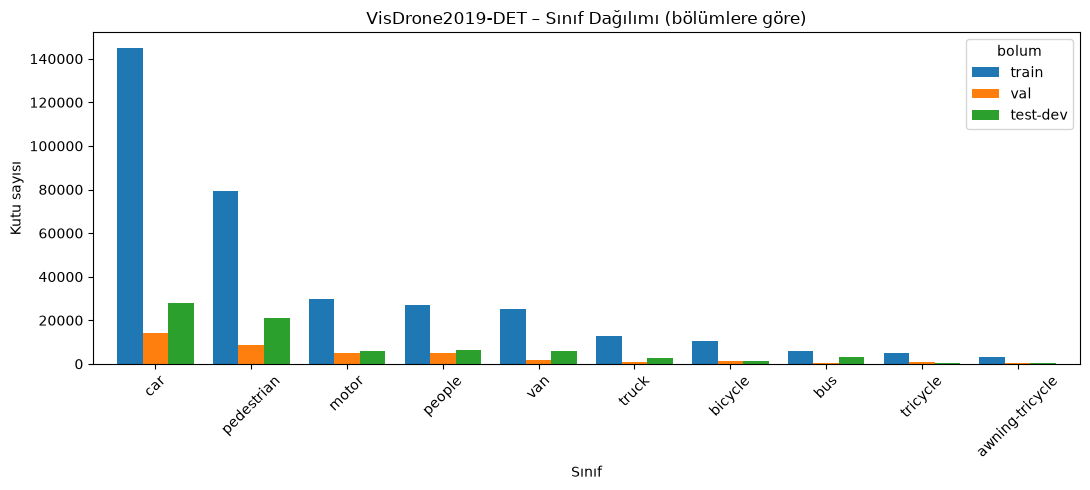

bolum,train,val,test-dev
sinif,,,
car,144867,14064,28074
pedestrian,79337,8844,21006
motor,29647,4886,5845
people,27059,5125,6376
van,24956,1975,5771
truck,12875,750,2659
bicycle,10480,1287,1302
bus,5926,251,2940
tricycle,4812,1045,530


In [4]:
siniflar = df[df["category"].between(1, 10)]
dagilim = pd.crosstab(siniflar["sinif"], siniflar["bolum"])
dagilim = dagilim[["train", "val", "test-dev"]].sort_values("train", ascending=False)

ax = dagilim.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("VisDrone2019-DET – Sınıf Dağılımı (bölümlere göre)")
ax.set_xlabel("Sınıf")
ax.set_ylabel("Kutu sayısı")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURLER / "visdrone_sinif_dagilimi.png", dpi=150)
plt.show()

dagilim